# Étude des retards des TGV en France (2018–2026)

## Pourquoi cette analyse ?

Quand on prend le train, on aimerait surtout arriver à l'heure. Mais est-ce que les retards des TGV ont augmenté ou diminué au fil des années ? C'est la question à laquelle je vais essayer de répondre avec les données disponibles.

Pour cela, j'utilise un fichier de la SNCF qui contient des informations mensuelles sur les trajets TGV : les gares de départ et d'arrivée, les trains prévus, les annulations et les retards.

**Ma question principale est donc : comment le taux de trains en retard de plus de 15 minutes a-t-il évolué entre 2018 et septembre 2026 ?**

Je vais avancer en plusieurs étapes :
1. Regarder ce que contient le fichier et vérifier la qualité des données.
2. Calculer le taux de retard chaque mois.
3. Observer son évolution sur un graphique.
4. Comparer les années, puis refaire la comparaison sur les mêmes mois pour ne pas désavantager 2026, dont les données s'arrêtent en septembre.

L'idée n'est pas de chercher tout de suite les causes des retards. Je veux d'abord voir ce que les chiffres nous disent, sans leur faire dire plus que ce qu'ils montrent.

**À garder en tête :** les résultats portent sur les observations présentes dans ce fichier. Ils ne doivent pas être confondus automatiquement avec un indicateur officiel de ponctualité pour tout le réseau TGV.


In [35]:
import pandas as pd
df = pd.read_csv("regularite-mensuelle-tgv-aqst.csv", sep=";")
df.head(10)

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386
5,2018-01,National,ST MALO,PARIS MONTPARNASSE,158,92,0,NaN,2,1.225000,...,6,4.763978,3,1,22.222222,66.666667,0.000000,11.111111,0.000000,0.000000
6,2018-01,National,TOULOUSE MATABIAU,PARIS MONTPARNASSE,257,184,0,NaN,23,11.221739,...,26,7.510507,12,3,59.090909,22.727273,4.545455,9.090909,4.545455,0.000000
7,2018-01,National,VANNES,PARIS MONTPARNASSE,156,278,1,NaN,168,5.120437,...,25,6.241487,11,3,24.137931,44.827586,20.689655,3.448276,3.448276,3.448276
8,2018-01,National,REIMS,PARIS EST,46,230,1,NaN,93,7.432796,...,20,3.538937,3,0,17.948718,41.025641,20.512821,5.128205,0.000000,15.384615
9,2018-01,National,DOUAI,PARIS NORD,77,197,3,NaN,39,8.032906,...,10,5.046907,5,3,36.363636,18.181818,22.727273,18.181818,4.545455,0.000000


## 1. Découvrir les données

Je commence par regarder la taille du fichier, les colonnes disponibles et quelques statistiques simples. Cela m'aide à comprendre ce que je peux analyser avant de faire des calculs.

In [36]:
df.describe()

,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Commentaire retards au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
count,12907.000000,12907.000000,12907.000000,0.0,12907.000000,12907.000000,12907.000000,0.0,12907.000000,12907.000000,...,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000,12907.000000
mean,170.693112,273.443635,8.273650,NaN,86.703882,12.598479,3.218180,NaN,38.874797,35.618496,...,28.101418,37.044197,13.328349,5.490819,22.204867,21.071536,19.690203,19.097682,8.177636,7.646645
std,87.726724,184.117868,21.805356,NaN,88.749586,11.584859,5.016502,NaN,32.454431,15.611291,...,23.911428,19.334086,13.030851,6.388148,16.211847,14.998078,14.926445,13.618080,9.302347,9.504751
min,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,-229.269444,NaN,0.000000,-40.109259,...,0.000000,-4.000000,-44.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,99.000000,151.000000,0.000000,NaN,22.000000,6.432137,1.250273,NaN,16.000000,26.091113,...,11.000000,29.084910,4.000000,1.000000,10.937500,11.111111,9.090909,10.000000,0.000000,0.000000
50%,163.000000,231.000000,2.000000,NaN,52.000000,10.696078,2.400417,NaN,30.000000,33.895833,...,22.000000,38.232979,10.000000,3.000000,20.000000,19.631094,18.181818,17.307692,6.122449,5.128205
75%,223.000000,365.000000,7.000000,NaN,127.000000,16.231349,4.094720,NaN,53.000000,42.912828,...,38.000000,47.664250,18.000000,7.000000,30.769231,28.888889,28.070175,25.806452,11.764706,11.111111
max,786.000000,1104.000000,297.000000,NaN,598.000000,316.188095,115.047390,NaN,376.000000,299.600000,...,312.000000,299.600000,202.000000,77.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000


### Vérifier les dates et les trajets

Je veux savoir depuis quand les données sont disponibles, combien de mois sont couverts et si les mêmes trajets apparaissent régulièrement. Je vérifie aussi si certaines lignes semblent répétées.

In [37]:
#sélectionne la colonne des dates.renvois la plus ancienne date et la plus récente
df["Date"].min(), df["Date"].max()

('2018-01', '2026-09')

In [38]:
#sélectionne la colonne des dates.compte le nombre de valeurs distinctes
df["Date"].nunique()

105

In [39]:
df.groupby(["Gare de départ", "Gare d'arrivée"])["Date"].nunique().describe()

count    130.000000
mean      98.961538
std       22.074716
min       12.000000
25%      105.000000
50%      105.000000
75%      105.000000
max      105.000000
Name: Date, dtype: float64

In [40]:
nb_mois = df.groupby(
    ["Gare de départ", "Gare d'arrivée"]
)["Date"].nunique()

(nb_mois == 105).sum()

np.int64(114)

In [41]:
df.duplicated(
    subset=["Date", "Gare de départ", "Gare d'arrivée"]
).sum()

np.int64(42)

In [42]:
colonnes = ["Date", "Gare de départ", "Gare d'arrivée"]

doublons = df[
    df.duplicated(subset=colonnes, keep=False)
].sort_values(by=colonnes)

doublons.head(10)

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
11055,2025-07,National,BELLEGARDE (AIN),PARIS LYON,179,22,0,NaN,13,13.397436,...,1,33.133333,1,0,0.000000,100.000000,0.000000,0.000000,0.000000,0.000000
11130,2025-07,International,BELLEGARDE (AIN),PARIS LYON,161,231,1,NaN,119,9.936275,...,35,51.177143,21,9,34.042553,19.148936,34.042553,4.255319,2.127660,6.382979
11078,2025-07,International,CHAMBERY CHALLES LES EAUX,PARIS LYON,176,96,13,NaN,66,12.532323,...,33,39.391919,13,7,22.857143,22.857143,22.857143,25.714286,2.857143,2.857143
11137,2025-07,National,CHAMBERY CHALLES LES EAUX,PARIS LYON,174,148,1,NaN,87,9.897701,...,41,39.070732,17,6,20.000000,18.000000,24.000000,30.000000,6.000000,2.000000
11102,2025-07,International,DIJON VILLE,PARIS LYON,95,186,1,NaN,71,15.678404,...,19,74.431579,13,10,50.000000,20.833333,16.666667,4.166667,8.333333,0.000000
11138,2025-07,National,DIJON VILLE,PARIS LYON,101,220,3,NaN,85,8.809020,...,13,44.653846,5,2,25.000000,25.000000,6.250000,31.250000,12.500000,0.000000
11164,2025-07,International,LYON PART DIEU,MARSEILLE ST CHARLES,99,62,1,NaN,36,19.947685,...,15,59.350000,6,3,22.222222,5.555556,50.000000,5.555556,5.555556,11.111111
11173,2025-07,National,LYON PART DIEU,MARSEILLE ST CHARLES,105,495,7,NaN,272,17.520711,...,111,54.138288,61,29,17.910448,20.255864,33.688699,15.351812,5.223881,7.569296
11061,2025-07,National,MACON LOCHE,PARIS LYON,98,163,0,NaN,134,15.848756,...,44,38.557197,18,6,18.518519,18.518519,24.074074,31.481481,5.555556,1.851852
11080,2025-07,International,MACON LOCHE,PARIS LYON,97,65,8,NaN,56,23.208929,...,29,37.862644,11,5,16.129032,25.806452,25.806452,29.032258,3.225806,0.000000


In [43]:
df.duplicated(
    subset=[
        "Date",
        "Service",
        "Gare de départ",
        "Gare d'arrivée"
    ]
).sum()

np.int64(0)

### Chercher les valeurs manquantes et vérifier les types

Avant de calculer un taux, je regarde si certaines informations sont absentes. Je vérifie également que Python reconnaît bien les dates : au départ, elles sont lues comme du texte, il faut donc les convertir.

In [44]:
#valeurs manquantes
df.isna().sum()

Date                                                                                               0
Service                                                                                            0
Gare de départ                                                                                     0
Gare d'arrivée                                                                                     0
Durée moyenne du trajet                                                                            0
Nombre de circulations prévues                                                                     0
Nombre de trains annulés                                                                           0
Commentaire annulations                                                                        12907
Nombre de trains en retard au départ                                                               0
Retard moyen des trains en retard au départ                                                

In [45]:
df.dtypes

Date                                                                                               str
Service                                                                                            str
Gare de départ                                                                                     str
Gare d'arrivée                                                                                     str
Durée moyenne du trajet                                                                          int64
Nombre de circulations prévues                                                                   int64
Nombre de trains annulés                                                                         int64
Commentaire annulations                                                                        float64
Nombre de trains en retard au départ                                                             int64
Retard moyen des trains en retard au départ                              

In [46]:
#conversion du type de date en datetime
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m")

In [47]:
df.dtypes

Date                                                                                           datetime64[us]
Service                                                                                                   str
Gare de départ                                                                                            str
Gare d'arrivée                                                                                            str
Durée moyenne du trajet                                                                                 int64
Nombre de circulations prévues                                                                          int64
Nombre de trains annulés                                                                                int64
Commentaire annulations                                                                               float64
Nombre de trains en retard au départ                                                                    int64
Retard moy

## 2. Vérifier les chiffres avant de les utiliser

Un train annulé fait normalement partie des trains qui étaient prévus. Je cherche donc les cas où le nombre d'annulations dépasse le nombre de circulations prévues.

Certaines lignes indiquent zéro circulation prévue alors qu'elles contiennent des annulations. Je les examine à part. Cela peut venir de la manière dont les données ont été déclarées, notamment pendant la période du Covid : je ne peux pas affirmer que ce sont des erreurs.

Pour calculer un taux de retard, j'écarte les lignes sans circulation prévue. Je garde toutefois le fichier de départ intact.

In [48]:
# Vérifier si le nombre de trains annulés dépasse le nombre de circulations prévues
# Une telle situation constituerait une incohérence dans les données

(df["Nombre de trains annulés"] > df["Nombre de circulations prévues"]).sum()

np.int64(63)

In [49]:
# Identifier les observations pour lesquelles le nombre de trains annulés
# dépasse le nombre de circulations prévues

anomalies = df[
    df["Nombre de trains annulés"] > df["Nombre de circulations prévues"]
]

# Afficher les 10 premières observations avec les variables pertinentes

anomalies[
    [
        "Date",
        "Service",
        "Gare de départ",
        "Gare d'arrivée",
        "Nombre de circulations prévues",
        "Nombre de trains annulés"
    ]
].head(10)

,Date,Service,Gare de départ,Gare d'arrivée,Nombre de circulations prévues,Nombre de trains annulés
3406,2020-04-01,National,PARIS MONTPARNASSE,ST MALO,0,8
3407,2020-04-01,National,PARIS MONTPARNASSE,TOURS,0,9
3409,2020-04-01,National,NANTES,STRASBOURG,0,2
3411,2020-04-01,National,PARIS NORD,DOUAI,0,12
3412,2020-04-01,National,DUNKERQUE,PARIS NORD,0,15
3414,2020-04-01,National,MARSEILLE ST CHARLES,TOURCOING,0,1
3415,2020-04-01,National,LYON PART DIEU,MARNE LA VALLEE,0,19
3416,2020-04-01,National,MARNE LA VALLEE,MARSEILLE ST CHARLES,0,14
3417,2020-04-01,National,MARSEILLE ST CHARLES,MARNE LA VALLEE,0,13
3418,2020-04-01,National,PARIS LYON,AIX EN PROVENCE TGV,0,17


In [50]:
# Compter les observations potentiellement incohérentes
# pour chaque mois concerné

anomalies.groupby("Date").size().sort_index()

Date
2020-04-01    50
2020-05-01     9
2020-06-01     4
dtype: int64

In [51]:
# Examiner le nombre de trains annulés lorsque
# aucune circulation n'est indiquée comme prévue

df.loc[
    df["Nombre de circulations prévues"] == 0,
    ["Nombre de circulations prévues", "Nombre de trains annulés"]
].describe()

,Nombre de circulations prévues,Nombre de trains annulés
count,73.0,73.000000
mean,0.0,6.643836
std,0.0,5.812749
min,0.0,0.000000
25%,0.0,1.000000
50%,0.0,4.000000
75%,0.0,12.000000
max,0.0,21.000000


In [52]:
# Création d'un jeu de données pour les analyses nécessitant
# un nombre de circulations prévues strictement positif.
# Le DataFrame original df reste inchangé.

df_analyse = df.loc[
    df["Nombre de circulations prévues"] > 0
].copy()

# Vérification du nombre d'observations conservées et exclues
print(f"Observations initiales : {len(df)}")
print(f"Observations conservées : {len(df_analyse)}")
print(f"Observations exclues : {len(df) - len(df_analyse)}")

Observations initiales : 12907
Observations conservées : 12834
Observations exclues : 73


### Calcul du taux de retard mensuel des TGV

Afin d'évaluer la ponctualité des TGV, nous avons choisi de calculer, pour chaque mois, la proportion de trains ayant enregistré un retard supérieur à 15 minutes.

Pour cela, nous considérons uniquement les trains effectivement réalisés, c'est-à-dire les circulations prévues auxquelles nous retirons les trains annulés.

Le nombre de trains réalisés est donc défini par :

$$
N_{\text{réalisés},t}
=
N_{\text{prévus},t}
-
N_{\text{annulés},t}
$$

où :

- $N_{\text{prévus},t}$ représente le nombre total de circulations prévues au cours du mois $t$ ;
- $N_{\text{annulés},t}$ désigne le nombre de trains annulés pendant ce même mois ;
- $N_{\text{réalisés},t}$ correspond au nombre de trains ayant effectivement circulé.

Le taux mensuel de retard est ensuite calculé selon la formule :

$$
\boxed{
R_t =
\frac{N_{\text{retard}>15,t}}
{N_{\text{réalisés},t}}
\times 100
}
$$

avec :

- $R_t$ : le taux de retard du mois $t$, exprimé en pourcentage ;
- $N_{\text{retard}>15,t}$ : le nombre total de trains ayant enregistré un retard supérieur à 15 minutes au cours du mois $t$ ;
- $N_{\text{réalisés},t}$ : le nombre total de trains effectivement réalisés pendant ce mois.

**Pourquoi ne pas simplement calculer la moyenne des taux de retard des différentes liaisons ?**

Toutes les liaisons ferroviaires ne présentent pas le même volume de circulation. Certaines comptabilisent plusieurs centaines de trains par mois, tandis que d'autres en enregistrent beaucoup moins.

Calculer une moyenne arithmétique des taux de retard reviendrait donc à accorder le même poids à toutes les liaisons, indépendamment du nombre de trains concernés.

Prenons un exemple simple :

- **Liaison A :** 100 trains réalisés, dont 10 en retard, soit un taux de 10 %.
- **Liaison B :** 200 trains réalisés, dont 40 en retard, soit un taux de 20 %.

La moyenne arithmétique des deux taux donnerait :

$$
\bar R = \frac{10+20}{2}=15\%
$$

Cependant, sur l'ensemble des deux liaisons, nous avons 50 trains en retard parmi 300 trains réalisés.

Le taux global est donc :

$$
R=\frac{10+40}{100+200}\times100
=\boxed{16,67\%}
$$

Ce résultat est plus représentatif de la proportion réelle de trains en retard sur l'ensemble du réseau étudié.

**Notre choix méthodologique**

Nous privilégions donc un calcul fondé sur le rapport entre le nombre total de trains en retard et le nombre total de trains réalisés.

Cette approche revient à calculer une moyenne des taux de retard des différentes liaisons, pondérée par leurs volumes respectifs de circulation.

Elle permet ainsi de tenir compte de l'importance relative de chaque liaison et d'obtenir un indicateur global plus pertinent pour analyser l'évolution de la ponctualité des TGV.

Enfin, cet indicateur mesure uniquement les retards supérieurs à 15 minutes. Il ne prend pas directement en compte les annulations, qui constituent une autre dimension de la qualité du service ferroviaire et pourront faire l'objet d'une analyse distincte.

In [53]:
# Calcul du nombre de trains effectivement réalisés
# en retirant les annulations des circulations prévues
df_analyse["Trains réalisés"] = (
    df_analyse["Nombre de circulations prévues"]
    - df_analyse["Nombre de trains annulés"]
)

# Vérifier combien d'observations présentent
# un nombre de trains réalisés nul ou négatif
(df_analyse["Trains réalisés"] <= 0).sum()

np.int64(0)

In [54]:
# Regrouper les données par mois et sommer les effectifs
# pour calculer un taux de retard global pondéré par le trafic

retards_mensuels = df_analyse.groupby("Date").agg({
    "Nombre trains en retard > 15min": "sum",
    "Trains réalisés": "sum"
})

# Calculer le pourcentage mensuel de trains
# arrivés avec plus de 15 minutes de retard
retards_mensuels["Taux retard (%)"] = (
    100
    * retards_mensuels["Nombre trains en retard > 15min"]
    / retards_mensuels["Trains réalisés"]
)

# Afficher les cinq premières observations
retards_mensuels.head()

,Nombre trains en retard > 15min,Trains réalisés,Taux retard (%)
Date,,,
2018-01-01,3496,34994,9.990284
2018-02-01,4959,31686,15.650445
2018-03-01,3415,34529,9.890237
2018-04-01,2647,24402,10.847472
2018-05-01,3195,27251,11.724340


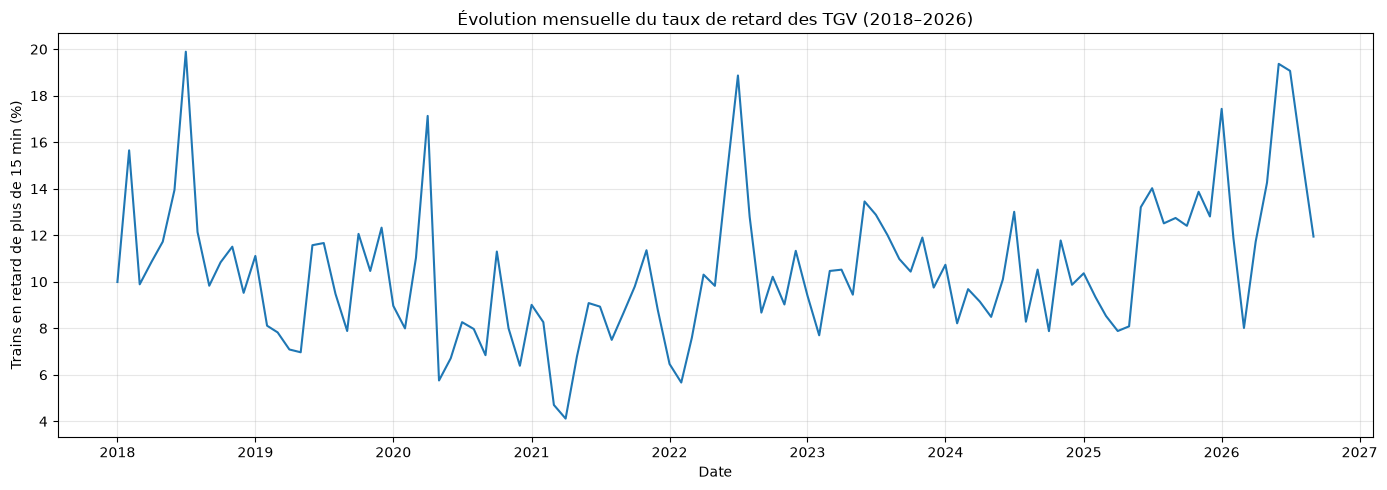

In [55]:
# Importer la bibliothèque de visualisation
import matplotlib.pyplot as plt

# Créer une figure
plt.figure(figsize=(14, 5))

# Représenter l'évolution mensuelle du taux de retard
plt.plot(
    retards_mensuels.index,
    retards_mensuels["Taux retard (%)"],
    linewidth=1.5
)

# Ajouter les éléments descriptifs du graphique
plt.title("Évolution mensuelle du taux de retard des TGV (2018–2026)")
plt.xlabel("Date")
plt.ylabel("Trains en retard de plus de 15 min (%)")

# Ajouter une grille pour faciliter la lecture
plt.grid(alpha=0.3)

# Ajuster la disposition
plt.tight_layout()

# Afficher le graphique
plt.show()

### Analyse de l'évolution mensuelle du taux de retard des TGV (2018–2026)

Le graphique présente l'évolution mensuelle du pourcentage de trains accusant un retard supérieur à 15 minutes, sur la période allant de janvier 2018 à septembre 2026.

À première vue, on constate que le taux de retard varie considérablement d'un mois à l'autre, oscillant approximativement entre 4 % et 20 %. Cette variabilité montre que la ponctualité des TGV n'est pas constante au cours du temps.

Plusieurs observations se dégagent :

- **Entre 2018 et 2019**, les taux de retard connaissent des fluctuations importantes, avec notamment un pic proche de 20 % en 2018.
- **Entre 2020 et 2021**, on observe une diminution globale des retards, avec des niveaux particulièrement faibles en 2021. Cette évolution pourrait être liée à la réduction du trafic ferroviaire pendant la crise sanitaire, mais cette hypothèse reste à vérifier.
- **Entre 2022 et 2024**, les taux continuent de fluctuer, sans qu'une tendance clairement croissante ou décroissante se dégage.
- **À partir de 2025**, on remarque une remontée apparente du taux de retard, accompagnée de plusieurs pics importants en 2026.

Dans l'ensemble, cette première analyse met en évidence une forte variabilité temporelle de la ponctualité des TGV. Elle suggère également une possible dégradation de la régularité sur la période récente.

Toutefois, ces observations restent descriptives. Une analyse complémentaire, notamment à travers la comparaison des taux annuels et l'étude des variations saisonnières, sera nécessaire pour confirmer ces premières impressions.

## 4. Passer des mois aux années

Après avoir regardé les variations mensuelles, je calcule un taux pour chaque année. Là encore, j'additionne d'abord les trains en retard et les trains réalisés, puis je fais la division. Je n'utilise pas la simple moyenne des taux mensuels, car les mois n'ont pas tous le même nombre de trains.

In [56]:
# Regrouper les données mensuelles par année
# en additionnant les trains en retard et les trains réalisés

retards_annuels = retards_mensuels.groupby(
    retards_mensuels.index.year
)[["Nombre trains en retard > 15min", "Trains réalisés"]].sum()

# Calculer le taux annuel de retard
retards_annuels["Taux retard (%)"] = (
    retards_annuels["Nombre trains en retard > 15min"]
    / retards_annuels["Trains réalisés"]
    * 100
)

# Afficher les résultats
retards_annuels

,Nombre trains en retard > 15min,Trains réalisés,Taux retard (%)
Date,,,
2018,46557,383053,12.154193
2019,35326,368835,9.577724
2020,20563,250584,8.206031
2021,30396,366568,8.292049
2022,45432,430843,10.544908
2023,46410,430062,10.791467
2024,43124,439992,9.801087
2025,49193,434624,11.318519
2026,45704,318473,14.350981


### Analyse de l'évolution annuelle du taux de retard des TGV

L'agrégation des données par année permet d'avoir une vision plus globale de l'évolution de la ponctualité des TGV, en atténuant les fluctuations observées à l'échelle mensuelle.

Les résultats montrent que le taux de retard a connu plusieurs phases entre 2018 et 2026.

Nous observons d'abord une diminution progressive du taux de retard entre 2018 (12,15 %) et 2020 (8,21 %). Cette amélioration apparente doit toutefois être interprétée avec prudence, notamment en raison de la réduction importante du trafic ferroviaire pendant la crise sanitaire.

À partir de 2022, les taux repartent à la hausse, atteignant 10,79 % en 2023, avant de connaître une légère diminution en 2024 (9,80 %).

La période récente attire particulièrement notre attention. En 2025, le taux atteint 11,32 %, puis 14,35 % sur les neuf premiers mois de 2026, soit le niveau le plus élevé parmi les périodes présentées.

Cependant, les données de 2026 ne couvrent que les mois de janvier à septembre. Une comparaison avec les mêmes mois des années précédentes serait donc nécessaire pour déterminer si cette augmentation traduit une véritable dégradation de la ponctualité ou si elle s'explique en partie par des effets saisonniers.

Dans l'ensemble, cette analyse met en évidence une amélioration de la ponctualité jusqu'en 2020, suivie d'une remontée progressive des retards, particulièrement visible sur la période récente.

## 5. Comparer les années sur les mêmes mois

Le fichier va jusqu'en septembre 2026. Comparer les neuf mois de 2026 aux douze mois de 2025 ne serait pas tout à fait juste : certains mois peuvent être plus difficiles que d'autres.

Je reprends donc le calcul en gardant uniquement **janvier à septembre** pour chaque année. Ainsi, toutes les années sont comparées sur la même période.

In [57]:
# Sélectionner uniquement les observations de janvier à septembre
# pour comparer les différentes années sur une période identique
df_jan_sep = df_analyse[
    df_analyse["Date"].dt.month <= 9
].copy()

# Extraire l'année à partir de la colonne Date
df_jan_sep["Année"] = df_jan_sep["Date"].dt.year

# Regrouper les observations par année et additionner les effectifs
comparaison = df_jan_sep.groupby("Année")[
    ["Nombre trains en retard > 15min", "Trains réalisés"]
].sum()

# Calculer le taux de retard annuel sur les neuf premiers mois
# en tenant compte du volume de circulation
comparaison["Taux retard (%)"] = (
    comparaison["Nombre trains en retard > 15min"]
    / comparaison["Trains réalisés"]
    * 100
)

# Afficher les résultats
comparaison

,Nombre trains en retard > 15min,Trains réalisés,Taux retard (%)
Année,,,
2018,36016,283856,12.688124
2019,26763,294162,9.098048
2020,16076,198562,8.096212
2021,20279,264847,7.656874
2022,34672,325063,10.666240
2023,34505,318513,10.833153
2024,32501,331247,9.811712
2025,35110,326393,10.756971
2026,45704,318473,14.350981


### Comparaison des taux de retard sur une période identique (janvier–septembre)

Notre première analyse annuelle avait mis en évidence une augmentation importante du taux de retard en 2026. Toutefois, les données disponibles pour cette année ne couvrent que les neuf premiers mois, contrairement aux années précédentes.

Pour rendre notre comparaison plus pertinente, nous avons donc recalculé les taux de retard en considérant uniquement les mois de janvier à septembre pour chaque année.

Les résultats confirment notre première impression : **2026 présente le taux de retard le plus élevé de la période étudiée, avec 14,35 %**, contre 10,76 % en 2025 et 12,69 % en 2018.

L'écart entre 2025 et 2026 atteint ainsi 3,59 points de pourcentage, ce qui représente une augmentation notable en seulement un an.

Nous remarquons également que 2021 constitue l'année la plus favorable de notre étude, avec un taux de retard de 7,66 %. Depuis cette période, la ponctualité semble globalement s'être dégradée, malgré une amélioration temporaire observée en 2024.

Cette comparaison renforce donc l'hypothèse d'une dégradation récente de la ponctualité des TGV sur les liaisons étudiées.

Il convient néanmoins de rester prudent : nos résultats décrivent une évolution statistique, mais ne permettent pas d'en identifier les causes. Des facteurs comme les conditions météorologiques, les incidents techniques, les mouvements sociaux ou les perturbations du réseau pourraient contribuer à expliquer ces variations.

Une analyse complémentaire serait nécessaire pour déterminer le rôle de ces différents facteurs.

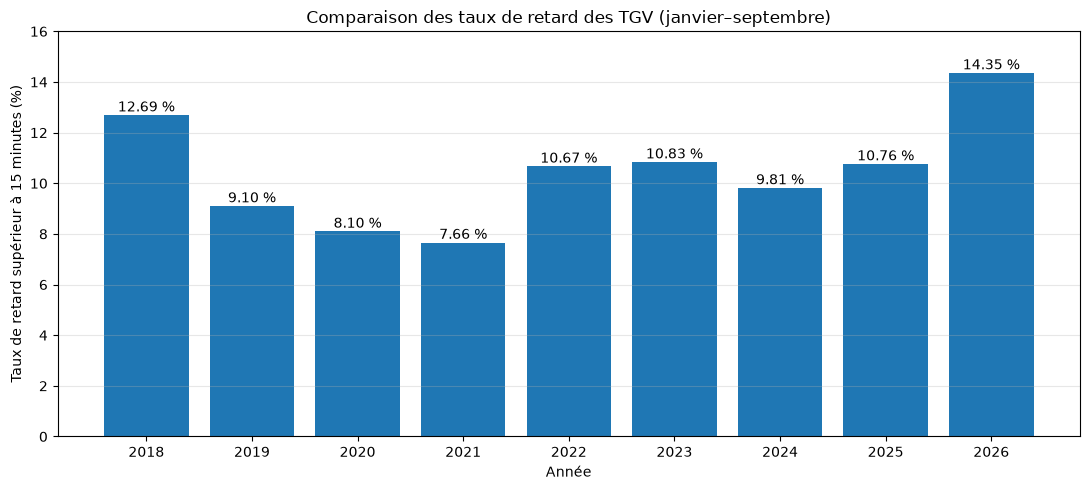

In [58]:
# Créer un diagramme en barres des taux de retard
# calculés sur la période janvier-septembre de chaque année

plt.figure(figsize=(11, 5))

plt.bar(
    comparaison.index.astype(str),
    comparaison["Taux retard (%)"]
)

# Ajouter les valeurs au-dessus des barres
for i, taux in enumerate(comparaison["Taux retard (%)"]):
    plt.text(
        i,
        taux + 0.15,
        f"{taux:.2f} %",
        ha="center"
    )

# Personnaliser le graphique
plt.title("Comparaison des taux de retard des TGV (janvier–septembre)")
plt.xlabel("Année")
plt.ylabel("Taux de retard supérieur à 15 minutes (%)")
plt.ylim(0, 16)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Interprétation du graphique

Ce graphique compare les taux de retard des TGV sur une période identique, de janvier à septembre, pour chaque année entre 2018 et 2026.

Nous constatons une amélioration progressive de la ponctualité entre 2018 et 2021, le taux passant de 12,69 % à 7,66 %. Cette tendance s'inverse ensuite, avec une remontée des retards à partir de 2022.

L'année 2026 se distingue particulièrement, avec un taux de retard de **14,35 %**, contre **10,76 % en 2025**, soit une augmentation de 3,59 points de pourcentage.

Il s'agit du taux le plus élevé parmi les années étudiées, même en comparant des périodes identiques.

Ces résultats suggèrent donc une dégradation récente de la ponctualité sur les liaisons étudiées. Toutefois, cette analyse reste descriptive et ne permet pas, à elle seule, d'expliquer les causes de cette évolution.